In [1]:
# Import necessary libraries
import os
import sys
import torch
import matplotlib.pyplot as plt
import numpy as np
import configparser
sys.path.append("..")
from pinns import rtpinn


In [2]:
# Set paths using config file
config = configparser.ConfigParser()
config.read('../init_file.ini')
figs_path = config['PATHS']['figs_path']


# Create the RTPINN object and train

In [3]:
tr_pr = {
    'sampling_method': "sobol",
    'sampling_seed': 21,
    'n_coll': 10000,
    'n_b': 1000,
    "epochs": 200,
    "epochs_adam": 0,
    "steps_lbfgs": 1,
    "nmom": 32,
    "I_0": 1,
    "scaling_factor": 1,
    "N_S": 16,
    "N_R": 16,
    "scenario_type": "lrt",
    "scenario_name": "sza_0_continental_clean_02",
    "brdf_dict": None,
    "save_results": True,
    "final_loss": 1,
    "train_time": 0,
}
# Model parameters
model_pr = {
    "model_name": "temp_name",
    "hidden_layers": 6,
    "neurons": 100,
    "residual_parameter": 1,
    "activation": "tanh",
    "n_mode": 1,
    'load_model': "no model",
    'save_model': False,
    'retrain': False,
}
# Initialize the RTPINN Model
rt_obj = rtpinn.RTPINN(tr_pr, model_pr)
model = rt_obj.solve_rte(model_pr)
print(f"Model name: {model_pr['model_name']}")


{'I_0': 1,
 'N_R': 16,
 'N_S': 16,
 'brdf_dict': None,
 'epochs': 200,
 'epochs_adam': 0,
 'final_loss': 1,
 'n_b': 1000,
 'n_coll': 10000,
 'nmom': 32,
 'sampling_method': 'sobol',
 'sampling_seed': 21,
 'save_results': True,
 'scaling_factor': 1,
 'scenario_name': 'sza_0_continental_clean_02',
 'scenario_type': 'lrt',
 'steps_lbfgs': 1,
 'train_time': 0}
************model properties************
{'activation': 'tanh',
 'hidden_layers': 6,
 'load_model': 'no model',
 'model_name': 'temp_name',
 'n_mode': 1,
 'neurons': 100,
 'residual_parameter': 1,
 'retrain': False,
 'save_model': False}
Fitting Model
Epoch: 0, Log Loss: 26.33061981201172
Epoch: 50, Log Loss: 0.0014880186645314097
Epoch: 100, Log Loss: 0.00037783404695801437
Epoch: 150, Log Loss: 0.0002237597364000976
**********
Training Time:
hours: 0.0
minutes: 1.0
seconds: 31.0
**********
Model name: temp_name


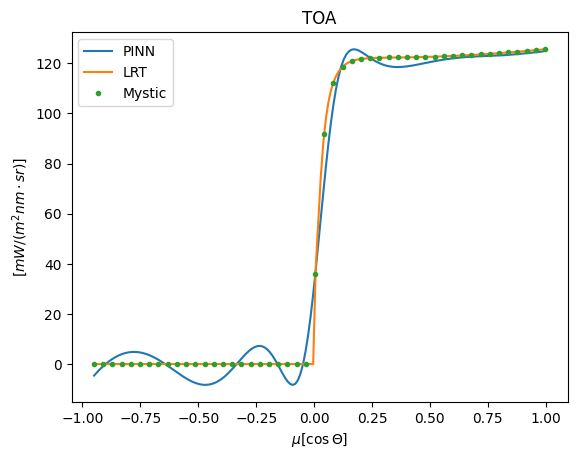

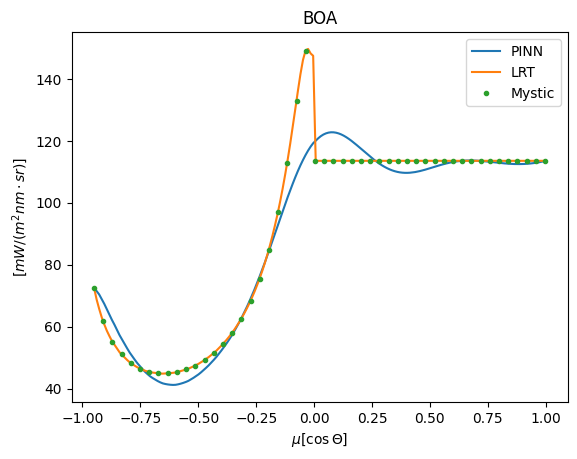

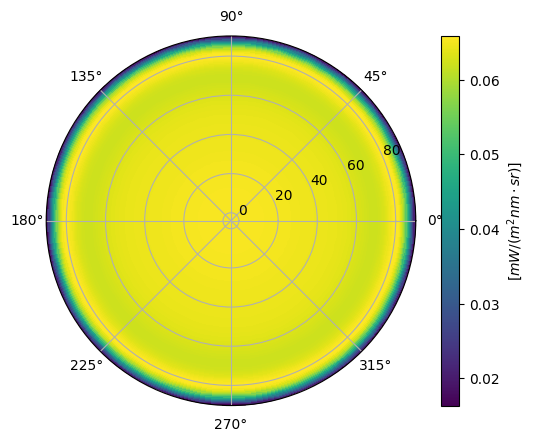

In [4]:
# Visualization
if tr_pr['scenario_type'] == "lrt":
    scenario_path = os.path.join(rtpinn.scenarios_path, 'lrt', tr_pr['scenario_name'])
    lrt_results = np.load(os.path.join(scenario_path, 'disort_output_file.npz'))

    # Plotting Top of Atmosphere (TOA) Radiance
    for ii in range(len(lrt_results['phi'])):
        tau_list = [0]
        correction_total = lrt_results['correction_st'][0, :, ii, 0] - lrt_results['correction_st'][0, :, ii, 1] - \
                           lrt_results['correction_nd'][0, :, ii]
        radiance_top_pinn = rtpinn.plot_1D(model, tau_list, lrt_results['mu'], (np.pi / 180) * lrt_results['phi'][ii],
                                       scale=lrt_results['scale'], label='PINN', fourier=True,
                                       correction=correction_total)
        plt.plot(lrt_results['mu'], lrt_results['radiance_mat'][0, :, ii], label='LRT')
        plt.plot(lrt_results['mu_lowres'], lrt_results['mystic_radiance'][0, :, ii], '.', label='Mystic')
        plt.legend()
        plt.title(f'TOA')
        plt.xlabel("$\mu [\cos{\Theta}]$")
        plt.ylabel("[$mW/(m^2 nm\cdot sr)]$")
        plt.savefig(f"{figs_path}/TOA_{model_pr['model_name']}.png", bbox_inches='tight')
        plt.show()

        # Plotting Bottom of Atmosphere (BOA) Radiance
        plt.figure()
        tau_star = rt_obj.total_optical_depth.detach().cpu().numpy()[-1]
        tau_list = [1.0]
        correction_total = lrt_results['correction_st'][1, :, ii, 0] - lrt_results['correction_st'][1, :, ii, 1] - \
                           lrt_results['correction_nd'][1, :, ii]
        radiance_top_pinn = rtpinn.plot_1D(model, tau_list, lrt_results['mu'], (np.pi / 180) * lrt_results['phi'][ii],
                                       scale=lrt_results['scale'], label='PINN', fourier=True,
                                       correction=correction_total)
        plt.plot(lrt_results['mu'], lrt_results['radiance_mat'][1, :, ii], label='LRT')
        plt.plot(lrt_results['mu_lowres'], lrt_results['mystic_radiance'][1, :, ii], '.', label='Mystic')
        plt.legend()
        plt.xlabel("$\mu [\cos{\Theta}]$")
        plt.ylabel("$[mW/(m^2 nm\cdot sr)]$")
        plt.title(f'BOA')
        plt.savefig(f"{figs_path}/BOA_{model_pr['model_name']}.png", bbox_inches='tight')
        plt.show()

# Heatmap Visualization (Optional)
heat_map = False
if heat_map:
    correction_total = lrt_results['correction_st'][:, :, 0, 0] - lrt_results['correction_st'][:, :, 0, 1] - \
                       lrt_results['correction_nd'][:, :, 0]
    tau_star = rt_obj.total_optical_depth.detach().cpu().numpy()[-1]
    avg_radiance_pinn = rtpinn.plot_heatmap(model, lrt_results['z_alt'], lrt_results['mu'],
                                        lrt_results['z_tau'],
                                        scale=lrt_results['scale'], correction=correction_total, tau_star=tau_star)
    plt.colorbar(label=r"$I(\tau,\mu)$ [$mW/(m^2 nm\cdot sr)]$")
    plt.ylabel(r'Altitude [km]')
    plt.xlabel(r'$\mu$')
    plt.savefig(f"{figs_path}/{model_pr['model_name']}_HeatMappinn.pdf", bbox_inches='tight')
    plt.show()

    error = np.abs((avg_radiance_pinn - lrt_results['avg_radiance']) / lrt_results['avg_radiance']) * 100
    error = np.clip(error, 0, 10)

    # Create the contourf plot
    X, Y = np.meshgrid(lrt_results['mu'], lrt_results['z_alt'])
    fig, ax = plt.subplots()
    contour = ax.contourf(X, Y, error, levels=np.linspace(0, 10, 11), cmap='jet', vmin=0, vmax=10)
    fig.colorbar(contour, label=r"$Relative\; Error [\%]$")
    ax.set_xlabel(r'$\mu$')
    ax.set_ylabel(r'$Altitude\; [km]$')
    plt.savefig(f"{figs_path}/{model_pr['model_name']}_HeatMapError.pdf", bbox_inches='tight')
    plt.show()

sky_map = True
if sky_map:
    mu = np.linspace(0, 1, 100)
    phi = np.linspace(0, 360, 100)
    tau_list = [0.0]
    pinn_rad = rtpinn.plot_skymap(model, tau_list, mu, phi * (np.pi / 180), direction='up',scale=1)
    plt.show()